# ¿Cuántos años puede leer un modelo en el ADN?
**Categoría: machine learning.**

Quiero comprobar cuánto me equivoco al predecir la edad cronológica de personas que no he usado para entrenar. Mi pregunta nace de las noticias sobre rejuvenecimiento, pero no mido longevidad, salud ni efectos de un tratamiento. Mi aportación es contrastar una predicción propia con una referencia sencilla y mirar en qué edades falla.

## Mi ruta de lectura
Primero documento los datos y su preparación. Después fijo las particiones, entreno, compruebo los errores y explico los límites. Puedo seguir el relato sin leer el código.

**Glosario:** llamo metilación a unas pequeñas marcas químicas del ADN; marcador a un punto donde las mido; chip a la pieza de laboratorio donde se procesaron varias muestras; entrenamiento al grupo con el que aprendo; prueba al grupo que reservo para comprobar el resultado. La edad objetivo son años cumplidos, no una supuesta edad biológica.

In [1]:
# localizo los archivos junto al cuaderno y dejo registradas las versiones
from pathlib import Path
import sys
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
raiz = Path.cwd()
assert (raiz / 'data/metilacion_candidatos.npz').exists(), 'Abro el cuaderno desde su carpeta completa.'
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit_learn': sklearn.__version__})


{'python': '3.12.10', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit_learn': '1.8.0'}


## 1. De dónde salen las muestras
Utilizo [GSE40279, depositado en GEO](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE40279), el conjunto de sangre de 656 personas empleado por Hannum y sus colaboradores en su [estudio original](https://pubmed.ncbi.nlm.nih.gov/23177740/). Cada fila de mi matriz representa una persona y cada columna una proporción de metilación entre cero y uno. Las edades van de 19 a 101 años. No presento la relación entre metilación y edad como un descubrimiento mío.

Distingo dos pasos reproducibles. Con `descargar_datos.py` conservo los originales y sus huellas. Con `preparar_datos.py` extraigo metadatos y una matriz compacta. El original ocupa más de un gigabyte comprimido y no lo duplico en la web.

Antes de calcular correlaciones, fijo una regla que no conoce las edades: solo considero identificadores `cg` cuyo número sea divisible entre 20. Publico **todos** esos candidatos, no solo las columnas que funcionaron. Así puedo repetir la selección y la validación completas con la descarga compacta. No utilizo las 71 marcas del reloj publicado: se eligieron originalmente con estas mismas personas y contaminarían mi comprobación.

In [2]:
# compruebo el tamaño, los ausentes y los códigos públicos antes de modelar
datos = np.load(raiz / 'data/metilacion_candidatos.npz')
muestras = pd.read_csv(raiz / 'data/muestras.csv', dtype={'chip': str})
preparacion = json.loads((raiz / 'data/preparacion.json').read_text(encoding='utf-8'))
assert datos['x'].shape == (len(muestras), len(datos['marcadores']))
assert muestras.muestra.is_unique and muestras.persona.is_unique
assert np.all([int(m[2:]) % 20 == 0 for m in datos['marcadores']])
display(pd.Series(preparacion, name='Comprobación'))
display(muestras.groupby('procedencia').agg(personas=('edad', 'size'), edad_minima=('edad', 'min'), edad_maxima=('edad', 'max')))


personas                                       656
candidatos                                   23734
chips                                           67
edad_minima                                     19
edad_maxima                                    101
ausentes                                         0
regla          identificador cg divisible entre 20
Name: Comprobación, dtype: object

,personas,edad_minima,edad_maxima
procedencia,,,
Boston,35,19,86
UCSD,304,23,101
USC,139,26,81
Utah,178,28,92


## 2. Qué decido antes de mirar el resultado
Conservo el [protocolo](protocolo.md) fijado antes del ajuste. Reservo aproximadamente un 20 % de las personas para prueba y un 15 % para calibración. Mantengo enteros los chips de laboratorio: ninguna de esas piezas aparece en dos particiones. Esto reduce una posible ventaja artificial, aunque no elimina todos los efectos de laboratorio ni equivale a probar en otra población.

Mi referencia consiste en contestar siempre la mediana de edad del entrenamiento. Frente a ella, ajusto una regresión ridge: una combinación de marcas que penaliza los pesos excesivos para no aprender detalles de memoria. Comparo cuatro combinaciones: 100 o 1.000 marcas, con penalización 10 o 100. Uso cinco vueltas de validación por chips dentro del entrenamiento.

En cada vuelta vuelvo a filtrar columnas con más de un 5 % de ausentes, reemplazo los huecos por la media del entrenamiento, retiro columnas constantes, selecciono marcas por su asociación con la edad y las pongo en una escala comparable. La selección no ve las edades reservadas. Elijo por error absoluto medio: cuántos años me equivoco, sin permitir que los errores hacia arriba y abajo se cancelen.

In [3]:
# ejecuto el protocolo completo; la búsqueda solo utiliza el entrenamiento
from modelo import ejecutar
particiones, predicciones, por_edad, metricas, validacion = ejecutar(raiz)
display(particiones.groupby('particion').agg(personas=('edad', 'size'), chips=('chip', 'nunique'), edad_minima=('edad', 'min'), edad_maxima=('edad', 'max')))
display(validacion[['param_seleccion__k', 'param_ridge__alpha', 'mean_test_score', 'std_test_score']].rename(columns={'mean_test_score': 'negativo_del_error_medio', 'std_test_score': 'dispersion_entre_vueltas'}))


Elección por validación: {'ridge__alpha': 100.0, 'seleccion__k': 1000} MAE 4.720539569854736


{
  "mae": 5.31703519821167,
  "mediana_error_absoluto": 4.404182434082031,
  "rmse": 7.3347146149435165,
  "r2": 0.8191398978233337,
  "mae_base": 14.047244094488189,
  "mediana_entrenamiento": 64.0,
  "mae_validacion": 4.720539569854736,
  "mejores_parametros": {
    "ridge__alpha": 100.0,
    "seleccion__k": 1000
  },
  "semianchura_intervalo_90": 9.638710021972656,
  "cobertura_prueba": 0.8661417322834646,
  "mae_ic95_por_chip": [
    4.275305634408849,
    6.521064311718118
  ],
  "particiones": {
    "entrenamiento": {
      "n": 420,
      "chips": 43
    },
    "calibracion": {
      "n": 109,
      "chips": 10
    },
    "prueba": {
      "n": 127,
      "chips": 14
    }
  }
}


,personas,chips,edad_minima,edad_maxima
particion,,,,
calibracion,109,10,26,93
entrenamiento,420,43,19,96
prueba,127,14,21,101


,param_seleccion__k,param_ridge__alpha,negativo_del_error_medio,dispersion_entre_vueltas
0,100,10.0,-5.654012,0.658154
1,1000,10.0,-4.992912,0.291071
2,100,100.0,-5.387692,0.726789
3,1000,100.0,-4.720540,0.397788


Leo las puntuaciones negativas cambiándoles el signo para obtener años de error. La combinación ganadora queda fijada por esas vueltas internas. No pruebo otros modelos después de abrir la prueba. Conservo las predicciones individuales y las particiones para poder auditarlo.

,Método,Error medio en años
0,Mediana del entrenamiento,14.047244
1,Modelo con metilación,5.317035


Error mediano: 4.40 años; raíz del error cuadrático: 7.33; R²: 0.819.


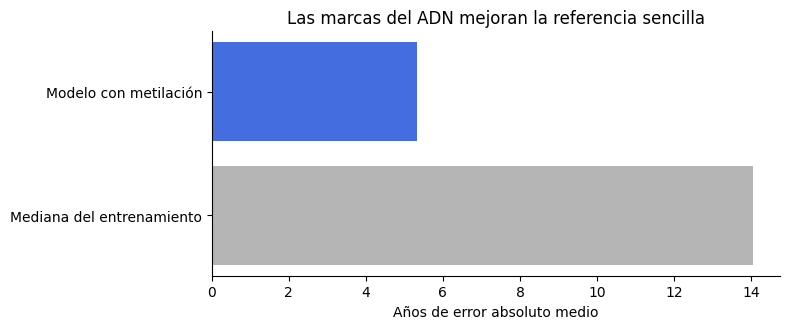

In [4]:
# comparo la predicción con una respuesta que ignora las marcas del adn
resumen = pd.DataFrame({'Método': ['Mediana del entrenamiento', 'Modelo con metilación'],
                       'Error medio en años': [metricas['mae_base'], metricas['mae']]})
display(resumen)
print(f"Error mediano: {metricas['mediana_error_absoluto']:.2f} años; raíz del error cuadrático: {metricas['rmse']:.2f}; R²: {metricas['r2']:.3f}.")
figura, eje = plt.subplots(figsize=(8, 3.4))
eje.barh(resumen['Método'], resumen['Error medio en años'], color=['#b5b5b5', '#446ddf'])
eje.set(xlabel='Años de error absoluto medio', title='Las marcas del ADN mejoran la referencia sencilla')
eje.spines[['top', 'right']].set_visible(False)
figura.tight_layout()
plt.show()


In [5]:
# traduzco el resultado a una lectura en palabras sin ocultar la incertidumbre
from IPython.display import Markdown, display
inferior, superior = metricas['mae_ic95_por_chip']
display(Markdown(f"En las **{len(predicciones)} personas de prueba**, me equivoco **{metricas['mae']:.2f} años de media**, frente a **{metricas['mae_base']:.2f}** de mi referencia. Al remuestrear chips completos, el intervalo orientativo del 95 % para ese error medio va de **{inferior:.2f} a {superior:.2f} años**. No es el intervalo de una persona: describe la incertidumbre del promedio y depende de los chips disponibles."))


En las **127 personas de prueba**, me equivoco **5.32 años de media**, frente a **14.05** de mi referencia. Al remuestrear chips completos, el intervalo orientativo del 95 % para ese error medio va de **4.28 a 6.52 años**. No es el intervalo de una persona: describe la incertidumbre del promedio y depende de los chips disponibles.

## 3. Acertar en promedio no significa acertar siempre
Comparo edad real y predicha. La diagonal representa un acierto perfecto; por encima asigno más años y por debajo menos. Cada punto pertenece únicamente a la prueba. Después separo edades con cortes fijados antes de entrenar. Un promedio general puede esconder errores diferentes en jóvenes y mayores.

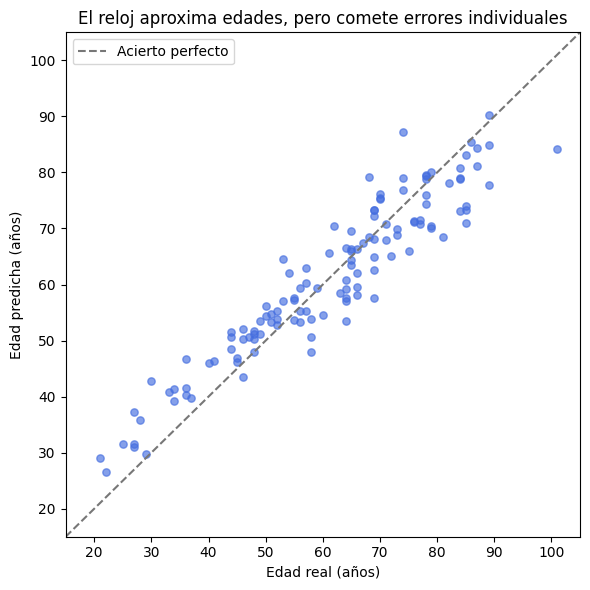

,n,edad_media,error_medio,mae,cobertura
grupo_edad,,,,,
19–39,16,30.125000,6.461635,6.461635,0.812500
40–59,40,50.825000,2.424034,3.948918,0.950000
60–79,54,69.740741,-0.364195,5.407588,0.907407
80 o más,17,86.294118,-7.018144,7.171227,0.588235


In [6]:
# dibujo las personas que el modelo no utilizó para aprender
figura, eje = plt.subplots(figsize=(6, 6))
eje.scatter(predicciones.edad, predicciones.prediccion, color='#446ddf', alpha=.65, s=28)
eje.plot([15, 105], [15, 105], color='#777777', linestyle='--', label='Acierto perfecto')
eje.set(xlabel='Edad real (años)', ylabel='Edad predicha (años)', title='El reloj aproxima edades, pero comete errores individuales', xlim=(15, 105), ylim=(15, 105))
eje.legend()
figura.tight_layout()
plt.show()
display(por_edad)


En esta prueba, interpreto una tendencia a acercar las edades al centro: asigno **6,46 años de más** a las 16 personas de 19–39 años y **7,02 de menos** a las 17 de 80 o más. No convierto esas diferencias en una medida de salud. Los tamaños pequeños y la ausencia de una cohorte externa limitan mi interpretación.

In [7]:
# explico el signo del error de cada grupo con sus tamaños
for grupo, fila in por_edad.iterrows():
    if fila['n']:
        sentido = 'más' if fila['error_medio'] > 0 else 'menos'
        print(f"En {grupo} años, con {int(fila['n'])} personas, asigno {abs(fila['error_medio']):.2f} años de {sentido} de media. El error absoluto medio es {fila['mae']:.2f} años.")


En 19–39 años, con 16 personas, asigno 6.46 años de más de media. El error absoluto medio es 6.46 años.
En 40–59 años, con 40 personas, asigno 2.42 años de más de media. El error absoluto medio es 3.95 años.
En 60–79 años, con 54 personas, asigno 0.36 años de menos de media. El error absoluto medio es 5.41 años.
En 80 o más años, con 17 personas, asigno 7.02 años de menos de media. El error absoluto medio es 7.17 años.


## 4. Cuánto margen necesita el reloj
Para no elegir el margen después de conocer la prueba, utilizo un grupo distinto de calibración. Ordeno sus errores absolutos y tomo el rango redondeado hacia arriba correspondiente al 90 %, con la corrección por tamaño de muestra. Añado y resto ese margen a cada predicción.

Es una calibración conformal sencilla. La cobertura nominal necesita supuestos de comparabilidad e independencia que los lotes pueden comprometer; por eso compruebo y cuento la cobertura observada en esta prueba, sin vender el 90 % como una garantía para cualquier persona. El margen se refiere a edad cronológica.

In [8]:
# cuento cuántas edades de prueba quedan dentro de la banda calibrada
cubiertas = int(predicciones.cubierto.sum())
display(Markdown(f"La banda tiene un margen de **±{metricas['semianchura_intervalo_90']:.2f} años**. Contiene **{cubiertas} de {len(predicciones)}** edades reales de prueba (**{metricas['cobertura_prueba']:.1%}**). Una predicción puntual por sí sola esconde ese margen."))
assert not set(particiones.loc[particiones.particion == 'prueba', 'chip']) & set(particiones.loc[particiones.particion == 'entrenamiento', 'chip'])
assert not set(particiones.loc[particiones.particion == 'calibracion', 'chip']) & set(particiones.loc[particiones.particion == 'prueba', 'chip'])
assert np.isfinite(predicciones.prediccion).all()
assert len(predicciones) == (particiones.particion == 'prueba').sum()


La banda tiene un margen de **±9.64 años**. Contiene **110 de 127** edades reales de prueba (**86.6%**). Una predicción puntual por sí sola esconde ese margen.

## 5. Qué puedo concluir y qué queda pendiente
Compruebo una predicción de edad cronológica en personas reservadas de una cohorte histórica. No he validado otra población, otro tejido ni otro laboratorio independiente. El tamaño de cada grupo de edad limita lo que puedo concluir. La composición celular de la sangre, la procedencia y otros factores pueden contribuir a la señal; no los separo causalmente.

No estudio personas antes y después de rejuvenecer, ni conozco su supervivencia posterior. Si una persona recibe una edad predicha menor que la real, solo observo un residuo de mi modelo. No puedo afirmar que esté más sana ni que vaya a vivir más. Tampoco presento este ejercicio reducido como una mejora del reloj científico original.

Mi conclusión responde a una pregunta acotada: puedo comprobar cuánto aprende un modelo sobre cumpleaños a partir de metilación y cuánto falla cuando lo pongo a prueba. Para evaluar una intervención de rejuvenecimiento necesitaría otros datos y otra pregunta.

## Fuentes y reproducción
- [GEO: GSE40279](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE40279).
- [Hannum et al., estudio original y DOI](https://pubmed.ncbi.nlm.nih.gov/23177740/).
- [Sumario de National Geographic, noviembre de 2026: punto de partida editorial](https://www.nationalgeographic.com.es/edicion-impresa/national-geographic-noviembre-2026_29672).

Instalo las versiones de `requirements.txt`, mantengo esta estructura de carpetas y ejecuto todas las celdas. La matriz compacta permite repetir el modelo completo. Si quiero auditar la extracción, ejecuto primero `descargar_datos.py` y `preparar_datos.py`, con espacio para la matriz original. No necesito cuentas ni bases de pago.